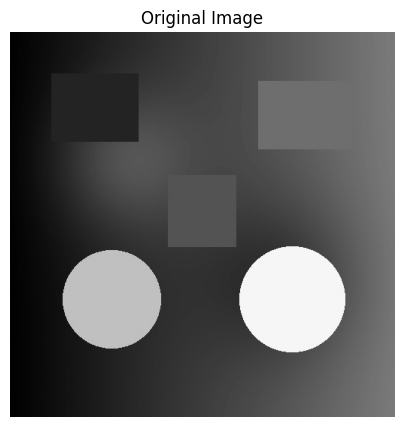

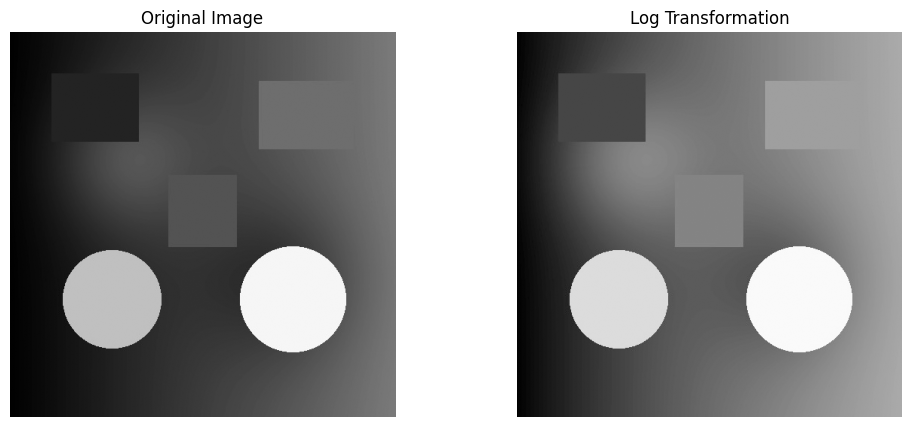

Enter the value of gamma: 0.5


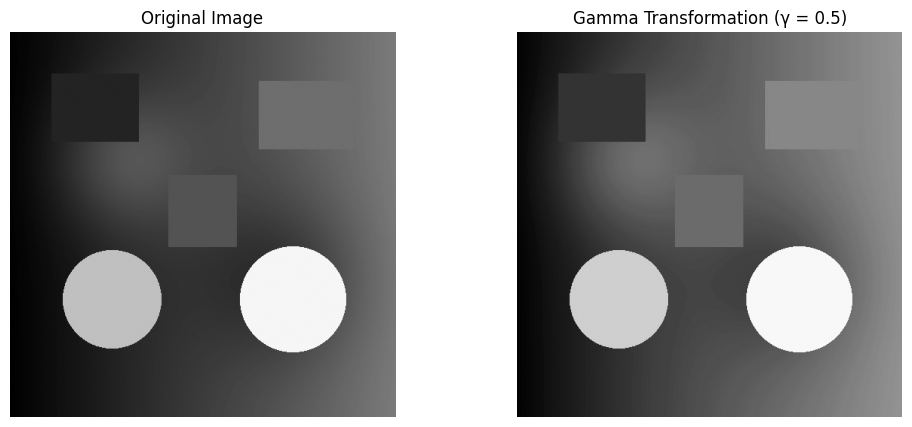

Enter lower input intensity: 80
Enter upper input intensity: 120
Enter lower output intensity: 100
Enter upper output intensity: 150


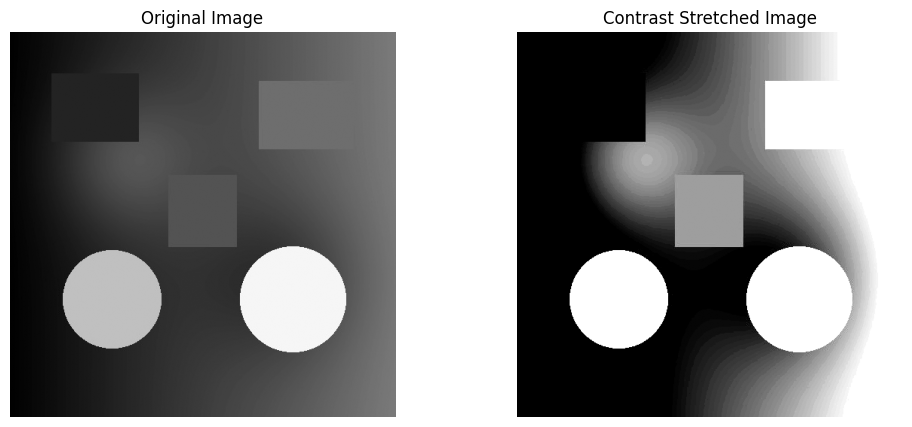


All three image enhancement operations completed successfully!

Output files:
1. log_transformed.jpg
2. gamma_transformed.jpg
3. contrast_stretched.jpg


In [4]:
# ============================================================
# IMAGE ENHANCEMENT - PART 1, PART 2, PART 3
# Google Colab / Python
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load image already uploaded to Colab
img = Image.open("input_image.jpg")

# Convert to grayscale
img = img.convert("L")

# Convert to NumPy array
img_array = np.array(img).astype(np.float64)

# Display original image
plt.figure(figsize=(6, 5))
plt.imshow(img_array, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()


# ============================================================
#                 PART 1: LOG TRANSFORMATION
# ============================================================



c = 1

log_img = c * np.log(1 + img_array)

log_img = 255 * (log_img - log_img.min()) / (log_img.max() - log_img.min())

log_img = log_img.astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(log_img, cmap='gray')
plt.title("Log Transformation")
plt.axis("off")

plt.show()

Image.fromarray(log_img).save("log_transformed.jpg")


# ============================================================
#          PART 2: POWER-LAW / GAMMA TRANSFORMATION
# ============================================================

gamma = float(input("Enter the value of gamma: "))

normalized_img = img_array / 255.0



gamma_img = normalized_img ** gamma

gamma_img = (gamma_img * 255).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gamma_img, cmap='gray')
plt.title(f"Gamma Transformation (γ = {gamma})")
plt.axis("off")

plt.show()

Image.fromarray(gamma_img).save("gamma_transformed.jpg")


# ============================================================
#              PART 3: CONTRAST STRETCHING
# ============================================================

r1 = float(input("Enter lower input intensity: "))
r2 = float(input("Enter upper input intensity: "))

s1 = float(input("Enter lower output intensity: "))
s2 = float(input("Enter upper output intensity: "))



stretch_img = (
    s1 + ((img_array - r1) * (s2 - s1) / (r2 - r1))
)

stretch_img[img_array <= r1] = s1

stretch_img[img_array >= r2] = s2

stretch_img = np.clip(stretch_img, 0, 255)

stretch_img = stretch_img.astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(stretch_img, cmap='gray')
plt.title("Contrast Stretched Image")
plt.axis("off")

plt.show()


Image.fromarray(stretch_img).save("contrast_stretched.jpg")



print("\nAll three image enhancement operations completed successfully!")

print("\nOutput files:")
print("1. log_transformed.jpg")
print("2. gamma_transformed.jpg")
print("3. contrast_stretched.jpg")